## **Análise Exploratória de Dados (EDA) de denúncias do Disque 100**

#### Análise de subconjunto de denúncias somente sobre tráfico de pessoas

**1. Informações sobre o conjunto de dados do Disque 100**

O Disque Direitos Humanos - Disque 100 é um serviço de utilidade pública do Ministério dos Direitos Humanos e da Cidadania, conforme previsto no Decreto nº 10.174, de 13 de dezembro de 2019, destinado a receber demandas relativas a violações de Direitos Humanos, especialmente as que atingem populações em situação de vulnerabilidade social[[1]](https://www.gov.br/pt-br/servicos/denunciar-violacao-de-direitos-humanos)[[2]](https://www.gov.br/mdh/pt-br/acesso-a-informacao/disque-100/disque-100)

**2. Considerações sobre taxonomia de classificação de denúncias**

São objetivos centrais:

- padronizar os dados obtidos pela ONDH em formato acessível ao cidadão;
- subsidiar o fomento e fortalecimento de políticas públicas afetas aos direitos humanos;
- racionalizar e uniformizar o fluxo de encaminhamento de denúncias relativas à violação de direitos humanos;
- facilitar o acesso e manejo das informações; e
- aprimorar o fluxo de informações com os demais órgãos governamentais responsáveis pelo recebimento das denúncias de violação aos direitos humanos, aproximando, na medida do possível, às nomenclaturas e estrutura de tabelas taxonômicas empregadas por cada um desses atores.

**3. Metodologia de embasamento da taxonomia da ONDH**

A metodologia apresenta, em detalhe, cada uma das **Classes, Subclasses, Espécies e Subespécies** que a compõe, discriminadas em uma escala de categorização de quatro níveis:

- Nível 01 – Direitos a serem tutelados sob a perspectiva dos direitos humanos.
- Nível 02 – Bem jurídico em sentido estrito.
- Nível 03 – Espécies de violações a determinado bem jurídico protegido.
- Nível 04 – Detalhamento de violações a determinada espécie.

**4. Violações de direitos humanos extraídas do manual relacionadas ao tráfico de pessoas**

Liberdade laboral

- 2.1. Liberdade Laboral (Subclasse) (p. 29)
- 2.1.1. Exploração do Trabalho (Espécie) (p. 29)
- 2.1.2. Impedimento de Trabalho/Ofício/Profissão (Espécie) (p. 29)

Condições análoga a de escravo

- 2.2.3. Condição Análoga à de Escravo (Espécie) (p. 31)
- 2.2.3.1. Submeter Trabalhador a Trabalhos Forçados (Subespécie) (p. 31)
- 2.2.3.2. Sujeitar Trabalhador a Condições Degradantes (Subespécie) (p. 33)
- 2.2.3.3. Submeter Trabalhador a Jornada Exaustiva (Subespécie) (p. 34)
- 2.2.3.4. Restringir a Locomoção de Trabalhador em Razão de Dívida (Subespécie) (p. 35)
- 2.2.3.5. Transportar Trabalhador Para Fins de Exploração (Subespécie) (p. 36)

Tráfico de pessoas

- 2.2.8. Tráfico de Pessoas – Internacional (Espécie) (p. 38)
- 2.2.9. Tráfico de Pessoas – Nacional (Espécie) (p. 39)

Exploração sexual

- 2.4.2.2. Exploração Sexual (Subespécie) (p. 44)

**5. Elementos circunstanciais**

**Elementos Circunstanciais** (indicadores de gravidade e de motivação) que poderão ser aplicados, conforme o caso concreto que envolva cada relato denunciado.```

- 2.22. Para fins de adoção
- 2.23. Para fins de atividade ilícita
- 2.24. Para fins de exploração sexual
- 2.25. Para fins de remoção de órgãos/tráfico de órgãos
- 2.26. Para fins de exploração do trabalho

Fonte: [Manual de Taxonomia de Direitos Humanos da ONDH](https://www.gov.br/mdh/pt-br/centrais-de-conteudo/publicacoes/ondh/manual-da-taxonomia-de-direitos-humanos-da-ondh.pdf)


In [2]:
# from google.colab import drive

import warnings
import os
from pathlib import Path
import pandas as pd
import numpy as np

from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
import plotly.io as pio
from plotly.subplots import make_subplots

pio.templates.default = 'plotly_white'
warnings.filterwarnings('ignore')
pio.renderers.default

pd.set_option('display.max_columns', 100)
# pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', '{:.2f}'.format)

In [7]:
DATA_FILENAME = 'trafico-pessoas-com-outras-violacoes-2021-2025.csv'

cwd = Path.cwd().resolve()
root_candidates = [cwd, cwd.parent]
project_root = next(
    (root for root in root_candidates if (root / 'pyproject.toml').is_file()
     and (root / 'data' / DATA_FILENAME).is_file()), None
)

In [8]:
disque100_path = project_root / "data" / "trafico-pessoas-com-outras-violacoes-2021-2025.csv"
print(f"Raiz do projeto: {project_root}")
print(f"Arquivo de dados: {disque100_path}")
print(f"Arquivo encontrado: {disque100_path.is_file()}")

Raiz do projeto: C:\Projetos\eda-disque100-completo
Arquivo de dados: C:\Projetos\eda-disque100-completo\data\trafico-pessoas-com-outras-violacoes-2021-2025.csv
Arquivo encontrado: True


In [9]:
df = pd.read_csv(disque100_path, sep=";", dtype='str')
print("Características do conjunto de dados")
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

Características do conjunto de dados
Linhas: 8401
Colunas: 62


In [10]:
df.head()

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,sl_quantidade_vitimas,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_da_vitima,doenca_rara_da_vitima,deficiencia_relacionada_a_doenca_rara,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,profissao_da_vitima,grau_de_instrucao_da_vitima,religiao_da_vitima,raca_cor_da_vitima,etnia_da_vitima,faixa_de_renda_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_do_suspeito,doenca_rara_do_suspeito,deficiencia_relacionada_a_doenca_rara_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
0,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,HÁ MAIS DE CINCO ANOS,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,PARA OBTENÇÃO DE BENEFÍCIO FINANCEIRO/ GANÂNCIA,OUTROS,PESSOA FÍSICA,FEMININO,N/D,NaN,N/D,NaN,NaN,NaN,N/D,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO BERNARDO DO CAMPO,N/D,N/D,N/D,N/D,N/D,N/D,PESSOA FÍSICA,MASCULINO,N/D,60 A 64 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO,NÃO,BRASIL,SP,SÃO BERNARDO DO CAMPO,N/D,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>CALÚNIA
1,0b9e67b28384351a4006c49ba3ff66b7,2021-01-14 07:11:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,HÁ MAIS DE SEIS MESES,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,DA COABITAÇÃO/ CONVIVÊNCIA FAMILIAR/ RELAÇÃO A...,FAMILIARES,PESSOA FÍSICA,FEMININO,N/D,02 A 04 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,ATÉ 1 SM,PESSOA FÍSICA,FEMININO,N/D,35 A 39 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO,NÃO,BRASIL,SP,SÃO PAULO,N/D,ENSINO FUNDAMENTAL INCOMPLETO,N/D,BRANCA,N/D,ATÉ 1 SM,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
2,6fa1ed73ec4c3f385683c9fc03a3c062,2021-01-12 07:34:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA DA VÍTIMA,BRASIL,SP,SÃO PAULO,DIARIAMENTE,HÁ MAIS DE SEIS MESES,20,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,DA COABITAÇÃO/ CONVIVÊNCIA FAMILIAR/ RELAÇÃO A...,PAI,PESSOA FÍSICA,FEMININO,N/D,02 A 04 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,N/D,PESSOA FÍSICA,MASCULINO,N/D,45 A 49 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO SABE INFORMAR,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,PRETA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
3,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,HÁ MAIS DE CINCO ANOS,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,RESULTANDO EM LESÃO GRAVÍSSIMA,OUTROS,PESSOA FÍSICA,FEMININO,N/D,NaN,N/D,NaN,NaN,NaN,N/D,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO BERNARDO DO CAMPO,N/D,N/D,N/D,N/D,N/D,N/D,PESSOA FÍSICA,MASCULINO,N/D,60 A 64 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO,NÃO,BRASIL,SP,SÃO BERNARDO DO CAMPO,N/D,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
4,ba12fedf0ff1a3bbe12b853e0ae2da65,2021-01-13 02:28:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,NÃO SABE INFORMAR,10,VIOLÊNCIA CONTRA PESSOA SOCIALMENTE VULNERÁVEL,PARA 

In [11]:
df.describe()

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,sl_quantidade_vitimas,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_da_vitima,doenca_rara_da_vitima,deficiencia_relacionada_a_doenca_rara,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,profissao_da_vitima,grau_de_instrucao_da_vitima,religiao_da_vitima,raca_cor_da_vitima,etnia_da_vitima,faixa_de_renda_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_do_suspeito,doenca_rara_do_suspeito,deficiencia_relacionada_a_doenca_rara_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
count,8401,8401,8401,8401,8401,8401,8401,7828,7810,8401,8401,8401,8401,2936,8401,8401,7267,6030,7996,8401,318,260,212,1988,7170,187,5938,8401,7813,7760,1375,1658,1215,8191,979,963,8401,6738,6723,5522,8392,386,355,270,1947,6743,947,5513,8401,7942,7896,5603,947,1170,4741,985,947,0,2396,974,991,8211
unique,1263,640,8,5,6,28,29,30,313,7,9,10,9,87,43,4,6,10,40,10,1,16,25,9,3,2,3,22,30,301,11,9,11,7,4,7,6,6,11,19,20,2,14,31,7,3,2,9,30,30,327,51,7,13,6,3,5,0,28,4,3,101
top,14FA196943254DCEE7558A46FD01F7C03D585E490D6F88...,2025-07-23 08:36:45,TELEFÔNICO,NÃO,TERCEIRO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BR | BRASIL,SP,DENUNCIANTE NÃO SOUBE INFORMAR,DIARIAMENTE,HÁ MAIS DE UM ANO,1,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,OUTRO(S) ELEMENTO(S),OUTROS,PESSOA FÍSICA,FEMININO,NÃO,CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA,BR | BRASIL,NATO,DENUNCIANTE NÃO SOUBE INFORMAR,SÃO PAULO,NÃO,NÃO,NÃO,NÃO,BR | BRASIL,SP,DENUNCIANTE NÃO SOUBE INFORMAR,N/D,N/D,N/D,NÃO INFORMADO,N/D,N/D,PESSOA FÍSICA,MASCULINO,NÃO,NÃO INFORMADO,BR | BRASIL,NATO,DENUNCIANTE NÃO SOUBE INFORMAR,SÃO PAULO,NÃO,NÃO,NÃO SABE INFORMAR,NÃO,BR | BRASIL,SP,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO SABE INFORMAR,N/D,N/D,BRANCA,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>TORTURA PSÍQUICA
freq,140,395,6091,7646,6642,1776,6498,1797,781,5173,2193,5093,5202,773,3726,6630,4100,4313,1191,7383,318,52,40,966,6223,177,4655,6552,1612,1225,916,819,887,3210,915,857,6522,3127,5585,955,7238,364,98,39,971,5796,730,3121,6746,1766,1038,1999,740,869,1715,915,785,NaN,925,915,933,535


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8401 entries, 0 to 8400
Data columns (total 62 columns):
 #   Column                                          Non-Null Count  Dtype
---  ------                                          --------------  -----
 0   hash                                            8401 non-null   str  
 1   data_de_cadastro                                8401 non-null   str  
 2   canal_de_atendimento                            8401 non-null   str  
 3   denuncia_emergencial                            8401 non-null   str  
 4   denunciante                                     8401 non-null   str  
 5   cenario_da_violacao                             8401 non-null   str  
 6   pais                                            8401 non-null   str  
 7   uf                                              7828 non-null   str  
 8   municipio                                       7810 non-null   str  
 9   frequencia                                      8401 non-null   str  
 10 

In [13]:
# convertendo data de cadastro para datetime [ns]
df["data_de_cadastro"] = pd.to_datetime(df["data_de_cadastro"], format="mixed", errors="coerce").astype("datetime64[ns]")
df["data_de_cadastro"] = df["data_de_cadastro"].dt.floor("s") 

# convertendo a quantidade de vítimas para numérico
df["sl_quantidade_vitimas"] = pd.to_numeric(df["sl_quantidade_vitimas"])

In [14]:
df.describe()

,data_de_cadastro,sl_quantidade_vitimas
count,8401,8401.00
mean,2024-05-15 21:53:36.963933184,3.29
min,2021-01-05 08:28:00,1.00
25%,2023-07-10 16:43:54,1.00
50%,2024-09-13 14:42:20,1.00
75%,2025-07-20 18:47:24,2.00
max,2025-12-30 15:31:58,60.00
std,NaN,7.47


In [15]:
df.columns

Index(['hash', 'data_de_cadastro', 'canal_de_atendimento',
       'denuncia_emergencial', 'denunciante', 'cenario_da_violacao', 'pais',
       'uf', 'municipio', 'frequencia', 'inicio_das_violacoes',
       'sl_quantidade_vitimas', 'grupo_vulneravel', 'motivacao',
       'relacao_vitima_suspeito', 'sl_vitima_cadastro', 'genero_da_vitima',
       'orientacao_sexual_da_vitima', 'faixa_etaria_da_vitima',
       'nacionalidade_da_vitima', 'sl_vitima_naturalidade',
       'sl_vitima_naturalizado_uf', 'sl_vitima_naturalizado_municipio',
       'deficiencia_da_vitima', 'doenca_rara_da_vitima',
       'deficiencia_relacionada_a_doenca_rara', 'vitima_preso_a',
       'pais_da_vitima', 'uf_da_vitima', 'municipio_da_vitima',
       'profissao_da_vitima', 'grau_de_instrucao_da_vitima',
       'religiao_da_vitima', 'raca_cor_da_vitima', 'etnia_da_vitima',
       'faixa_de_renda_da_vitima', 'natureza_juridica_do_suspeito',
       'genero_do_suspeito', 'orientacao_sexual_do_suspeito',
       'faixa_e

In [16]:
df.dtypes

hash                                       str
data_de_cadastro                datetime64[ns]
canal_de_atendimento                       str
denuncia_emergencial                       str
denunciante                                str
                                     ...      
vinculo_orgao_pj_do_suspeito               str
sl_suspeito_ramo                           str
suspeito_especificacao_etnia               str
vitima_especificacao_etnia                 str
violacao                                   str
Length: 62, dtype: object

In [17]:
datas = pd.read_csv(
    disque100_path,
    sep=";",
    usecols=["data_de_cadastro"],
    dtype="string",
)["data_de_cadastro"]

# Substitui dígitos por zeros, preservando estrutura e separadores.
padroes = datas.str.replace(r"\d", "0", regex=True)

resumo = (
    pd.DataFrame({"padrao": padroes, "exemplo": datas})
    .groupby("padrao")
    .agg(quantidade=("exemplo", "size"), exemplo=("exemplo", "first"))
    .sort_values("quantidade", ascending=False)
)

display(resumo)
print(f"Padrões textuais encontrados: {len(resumo)}")

,quantidade,exemplo
padrao,,
0000-00-00 00:00:00,8401,2021-01-08 23:11:00


Padrões textuais encontrados: 1


In [18]:
df[df["faixa_etaria_da_vitima"] == "VIDA INTRAUTERINA"][["hash", "data_de_cadastro", "violacao"]].sort_values(by="hash")

,hash,data_de_cadastro,violacao
556,36650f772993d399bcc3896083d17f8f,2022-05-18 22:15:00,DIREITOS SOCIAIS>PROTEÇÃO À INFÂNCIA
562,36650f772993d399bcc3896083d17f8f,2022-05-18 22:15:00,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
605,36650f772993d399bcc3896083d17f8f,2022-05-18 22:15:00,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
616,36650f772993d399bcc3896083d17f8f,2022-05-18 22:15:00,INTEGRIDADE>FÍSICA>OUTROS
321,421e9528b782ae18d2940581b3f8213e,2022-01-12 09:57:00,NaN
328,421e9528b782ae18d2940581b3f8213e,2022-01-12 09:57:00,DIREITOS SOCIAIS>PROTEÇÃO À INFÂNCIA
329,421e9528b782ae18d2940581b3f8213e,2022-01-12 09:57:00,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
594,874f3526e92b86b2dd694c2f1f71b314,2022-05-16 17:56:00,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
599,874f3526e92b86b2dd694c2f1f71b314,2022-05-16 17:56:00,DIREITOS SOCIAIS>PROTEÇÃO À INFÂNCIA
604,874f3526e92b86b2dd694c2f1f71b314,2022-05-16 17:56:00,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...


In [19]:
df[df["hash"] == "a30af00257ba98056f7ee4158b0a4a32"]

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,sl_quantidade_vitimas,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_da_vitima,doenca_rara_da_vitima,deficiencia_relacionada_a_doenca_rara,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,profissao_da_vitima,grau_de_instrucao_da_vitima,religiao_da_vitima,raca_cor_da_vitima,etnia_da_vitima,faixa_de_renda_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_do_suspeito,doenca_rara_do_suspeito,deficiencia_relacionada_a_doenca_rara_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
3660,a30af00257ba98056f7ee4158b0a4a32,2021-11-02 10:48:00,WEBCHAT,SITUAÇÃO FLAGRANTE - ATÉ 24H DA OCORRÊNCIA - S...,TERCEIRO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,PR,MEDIANEIRA,ÚNICA OCORRÊNCIA,NÃO SE APLICA,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,PARA FINS DE ADOÇÃO,MÃE,PESSOA FÍSICA,N/D,N/D,VIDA INTRAUTERINA,BRASIL,NaN,NaN,NaN,NÃO TEM DEFICIÊNCIA,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,PR,MEDIANEIRA,N/D,N/D,N/D,N/D,N/D,N/D,PESSOA FÍSICA,FEMININO,N/D,30 A 34 ANOS,BRASIL,NaN,NaN,NaN,NÃO TEM DEFICIÊNCIA,NÃO TEM DOENÇA RARA,NÃO SABE INFORMAR,N/D,BRASIL,PR,MEDIANEIRA,N/D,N/D,N/D,BRANCA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...


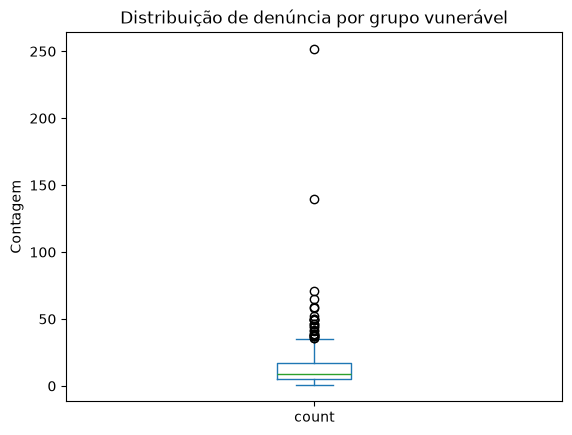

In [20]:
# df["faixa_etaria_da_vitima"] \
ax = df[["grupo_vulneravel", "faixa_etaria_da_vitima", "faixa_etaria_do_suspeito"]] \
    .value_counts() \
    .sort_values(ascending=False) \
    .plot(kind="box")
    # .sum()

ax.set_ylabel("Contagem")
plt.title("Distribuição de denúncia por grupo vunerável")
plt.show()

#### Verificação de registros duplicados


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8401 entries, 0 to 8400
Data columns (total 62 columns):
 #   Column                                          Non-Null Count  Dtype         
---  ------                                          --------------  -----         
 0   hash                                            8401 non-null   str           
 1   data_de_cadastro                                8401 non-null   datetime64[ns]
 2   canal_de_atendimento                            8401 non-null   str           
 3   denuncia_emergencial                            8401 non-null   str           
 4   denunciante                                     8401 non-null   str           
 5   cenario_da_violacao                             8401 non-null   str           
 6   pais                                            8401 non-null   str           
 7   uf                                              7828 non-null   str           
 8   municipio                                       7810 non-nu

`Mover para preparação dos dados`


In [22]:
import numpy as np
import pandas as pd

df_clean = df.copy()

# Garantir padronização do texto
df_clean["faixa_etaria_da_vitima"] = (
    df["faixa_etaria_da_vitima"]
    .astype(str)
    .str.upper()
    .str.strip()
)

MAPA_FAIXA_ETARIA = {

    # Vida intrauterina
    "VIDA INTRAUTERINA": "Vida intrauterina",

    # Primeira infância (0-5)
    "RECÉM-NASCIDO (ATÉ 28 DIAS)": "Primeira infância (0-6)",
    "RECÉM NASCIDO (ATÉ 90 DIAS ? 3 MESES)": "Primeira infância (0-6)",
    "MENOS DE 01 ANO": "Primeira infância (0-6)",
    "00 A 01 ANO": "Primeira infância (0-6)",
    "01 ANO": "Primeira infância (0-6)",
    "02 A 04 ANOS": "Primeira infância (0-6)",
    "02 ANOS": "Primeira infância (0-6)",
    "03 ANOS": "Primeira infância (0-6)",
    "04 ANOS": "Primeira infância (0-6)",
    "05 A 06 ANOS": "Primeira infância (0-6)",
    "05 ANOS": "Primeira infância (0-6)",
    "06 ANOS": "Primeira infância (0-6)",

    # Criança (6-11)
    "07 A 09 ANOS": "Criança (7-11)",
    "07 ANOS": "Criança (7-11)",
    "08 ANOS": "Criança (7-11)",
    "09 ANOS": "Criança (7-11)",
    "10 A 11 ANOS": "Criança (7-11)",
    "10 ANOS": "Criança (7-11)",
    "11 ANOS": "Criança (7-11)",

    # Adolescente (12-17)
    "12 A 14 ANOS": "Adolescente (12-17)",
    "12 ANOS": "Adolescente (12-17)",
    "13 ANOS": "Adolescente (12-17)",
    "14 ANOS": "Adolescente (12-17)",
    "15 A 17 ANOS": "Adolescente (12-17)",
    "15 ANOS": "Adolescente (12-17)",
    "16 ANOS": "Adolescente (12-17)",
    "17 ANOS": "Adolescente (12-17)",

    # Faixa infantojuvenil sem idade específica
    "CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA":
        "Criança ou adolescente (idade exata não informada)",

    # Jovem
    "18 A 19 ANOS": "Jovem (18-29)",
    "20 A 24 ANOS": "Jovem (18-29)",
    "25 A 29 ANOS": "Jovem (18-29)",

    # Adulto
    "30 A 34 ANOS": "Adulto (30-59)",
    "35 A 39 ANOS": "Adulto (30-59)",
    "40 A 44 ANOS": "Adulto (30-59)",
    "45 A 49 ANOS": "Adulto (30-59)",
    "50 A 54 ANOS": "Adulto (30-59)",
    "55 A 59 ANOS": "Adulto (30-59)",

    # Pessoa idosa
    "60 A 64 ANOS": "Pessoa idosa (60+)",

    # Não informado
    "NÃO INFORMADO": "Não informado",
}

df_clean["faixa_etaria_recodificada"] = (
    df["faixa_etaria_da_vitima"]
    .map(MAPA_FAIXA_ETARIA)
    .fillna("Não informado")
)

# Verificar distribuição final
print(df_clean["faixa_etaria_recodificada"].value_counts(dropna=False))

# Verificar possíveis categorias não tratadas
nao_mapeadas = (
    df_clean.loc[
        df_clean["faixa_etaria_recodificada"].isna(),
        "faixa_etaria_da_vitima"
    ]
    .value_counts()
)

print("\nCategorias não mapeadas:")
print(nao_mapeadas)

# Distribuição final
freq = (
    df_clean["faixa_etaria_recodificada"]
        .value_counts(dropna=False)
        .rename_axis("categoria")
        .reset_index(name="frequencia")
    )

print(freq)

ORDEM_FAIXA_ETARIA = {
    "Vida intrauterina": 0,
    "Primeira infância (0 a 6 anos)": 1,
    "Criança (7 a 11 anos)": 2,
    "Adolescente (12 a 17 anos)": 3,
    "Criança ou adolescente (idade exata não informada)": 4,
    "Jovem (18 a 29 anos)": 5,
    "Adulto (30 a 59 anos)": 6,
    "Pessoa idosa (60 anos ou mais)": 7,
    "Não informado": 8
}

df_clean["faixa_etaria_ordinal"] = (
    df_clean["faixa_etaria_recodificada"]
    .map(ORDEM_FAIXA_ETARIA)
)

faixa_etaria_recodificada
Adolescente (12-17)                                   2179
Jovem (18-29)                                         1642
Criança ou adolescente (idade exata não informada)    1191
Adulto (30-59)                                        1145
Primeira infância (0-6)                               1088
Criança (7-11)                                         635
Não informado                                          475
Pessoa idosa (60+)                                      33
Vida intrauterina                                       13
Name: count, dtype: int64

Categorias não mapeadas:
Series([], Name: count, dtype: int64)
                                           categoria  frequencia
0                                Adolescente (12-17)        2179
1                                      Jovem (18-29)        1642
2  Criança ou adolescente (idade exata não inform...        1191
3                                     Adulto (30-59)        1145
4                           

In [23]:
faixas = [
    (0, 6, "Primeira infância (0 a 6 anos)"),
    (7, 11, "Criança (7 a 11 anos)"),
    (12, 17, "Adolescente (12 a 17 anos)"),
    (18, 29, "Jovem (18 a 29 anos)"),
    (30, 59, "Adulto (30 a 59 anos)"),
    (60, 200, "Pessoa idosa (60 anos ou mais)")
]

excecoes = {
    "VIDA INTRAUTERINA": "Vida intrauterina",
    "CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA": (
        "Criança ou adolescente (idade exata não informada)"
    ),
    "NÃO INFORMADO": "Não informado"
}

import re
import pandas as pd
import numpy as np


def recodificar_faixa_etaria(
    valor,
    faixas,
    excecoes=None,
    estrategia_intervalo="menor"
):
    """
    Recodifica categorias de faixa etária.

    Parâmetros
    ----------
    valor : str
        Valor original da variável.

    faixas : list[tuple]
        Lista no formato:
        [
            (idade_min, idade_max, nome_categoria),
            ...
        ]

    excecoes : dict, opcional
        Categorias sem idade numérica.

    estrategia_intervalo : str
        Como tratar intervalos contendo dois números:
        - 'menor'  -> usa o menor valor encontrado
        - 'maior'  -> usa o maior valor encontrado
        - 'media'  -> média dos valores

    Retorna
    -------
    str
        Categoria recodificada.
    """

    if pd.isna(valor):
        return np.nan

    valor = str(valor).upper().strip()

    # Trata exceções primeiro
    if excecoes and valor in excecoes:
        return excecoes[valor]

    # Extrai todos os números do texto
    numeros = [int(x) for x in re.findall(r"\d+", valor)]

    if not numeros:
        return "Categoria não classificada"

    # Escolhe idade representativa
    if estrategia_intervalo == "menor":
        idade = min(numeros)

    elif estrategia_intervalo == "maior":
        idade = max(numeros)

    elif estrategia_intervalo == "media":
        idade = sum(numeros) / len(numeros)

    else:
        raise ValueError(
            "estrategia_intervalo deve ser "
            "'menor', 'maior' ou 'media'"
        )

    # Localiza a categoria
    for idade_min, idade_max, categoria in faixas:
        if idade_min <= idade <= idade_max:
            return categoria

    return "Categoria não classificada"

df2 = df.copy()

df2["faixa_etaria_recodificada"] = (
    df2["faixa_etaria_da_vitima"]
    .apply(
        lambda x: recodificar_faixa_etaria(
            valor=x,
            faixas=faixas,
            excecoes=excecoes,
            estrategia_intervalo="menor"
        )
    )
)

print(
    df2["faixa_etaria_recodificada"]
    .value_counts(dropna=False)
)

nao_classificadas = (
    df2.loc[
        df2["faixa_etaria_recodificada"] ==
        "Categoria não classificada",
        "faixa_etaria_da_vitima"
    ]
    .value_counts()
)

print(nao_classificadas)

faixa_etaria_recodificada
Adolescente (12 a 17 anos)                            2179
Jovem (18 a 29 anos)                                  1732
Criança ou adolescente (idade exata não informada)    1191
Adulto (30 a 59 anos)                                 1145
Primeira infância (0 a 6 anos)                         998
Criança (7 a 11 anos)                                  635
NaN                                                    405
Não informado                                           70
Pessoa idosa (60 anos ou mais)                          33
Vida intrauterina                                       13
Name: count, dtype: int64
Series([], Name: count, dtype: int64)


In [24]:
# verificando o número de registro duplicados
duplicados = df.duplicated(subset=df.columns.difference(["hash"]))
print(f"Quantidade registros duplicados, desconsiderando o hash: {duplicados.sum()}")

Quantidade registros duplicados, desconsiderando o hash: 930


In [25]:
df[duplicados].head(10).sort_values(by='data_de_cadastro', ascending=False)

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,sl_quantidade_vitimas,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_da_vitima,doenca_rara_da_vitima,deficiencia_relacionada_a_doenca_rara,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,profissao_da_vitima,grau_de_instrucao_da_vitima,religiao_da_vitima,raca_cor_da_vitima,etnia_da_vitima,faixa_de_renda_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_do_suspeito,doenca_rara_do_suspeito,deficiencia_relacionada_a_doenca_rara_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
963,67D62E1DB0620B7970F37B5E57B100B4AAFA19E4CBC7E1...,2023-03-28 14:43:23,TELEFÔNICO,NÃO,TERCEIRO,OUTROS,BR | BRASIL,PR,410690 | CURITIBA,DIARIAMENTE,HÁ MAIS DE UM ANO,1,"VIOLÊNCIA CONTRA CIDADÃO, FAMÍLIA OU COMUNIDADE",AGRAVANTE.DO AGRESSOR POSSUIR INFLUÊNCIA JUNTO...,OUTROS,COMUNIDADE/FAMÍLIA,NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA,NÃO INFORMADO,NÃO INFORMADO,BR | BRASIL,NaN,NaN,NaN,NaN,NÃO,NaN,NÃO,BR | BRASIL,PR,410690 | CURITIBA,OUTROS NÃO LISTADOS,SUPERIOR COMPLETO,NaN,NÃO INFORMADO,NaN,NaN,COMUNIDADE/FAMÍLIA,NaN,NaN,NaN,BR | BRASIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BR | BRASIL,PR,410690 | CURITIBA,NaN,NaN,NÃO SABE,NaN,DEMAIS COMUNIDADES TRADICIONAIS,NaN,NaN,NaN,NaN,OUTROS,INTEGRIDADE>FÍSICA>EXPOSIÇÃO DE RISCO À SAÚDE
992,67D62E1DB0620B7970F37B5E57B100B4AAFA19E4CBC7E1...,2023-03-28 14:43:23,TELEFÔNICO,NÃO,TERCEIRO,OUTROS,BR | BRASIL,PR,410690 | CURITIBA,DIARIAMENTE,HÁ MAIS DE UM ANO,1,"VIOLÊNCIA CONTRA CIDADÃO, FAMÍLIA OU COMUNIDADE","AGRAVANTE.EM MEIO DIGITAL (internet, Redes Soc...",OUTROS,COMUNIDADE/FAMÍLIA,NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA,NÃO INFORMADO,NÃO INFORMADO,BR | BRASIL,NaN,NaN,NaN,NaN,NÃO,NaN,NÃO,BR | BRASIL,PR,410690 | CURITIBA,OUTROS NÃO LISTADOS,SUPERIOR COMPLETO,NaN,NÃO INFORMADO,NaN,NaN,COMUNIDADE/FAMÍLIA,NaN,NaN,NaN,BR | BRASIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BR | BRASIL,PR,410690 | CURITIBA,NaN,NaN,NÃO SABE,NaN,DEMAIS COMUNIDADES TRADICIONAIS,NaN,NaN,NaN,NaN,OUTROS,INTEGRIDADE>NEGLIGÊNCIA
993,67D62E1DB0620B7970F37B5E57B100B4AAFA19E4CBC7E1...,2023-03-28 14:43:23,TELEFÔNICO,NÃO,TERCEIRO,OUTROS,BR | BRASIL,PR,410690 | CURITIBA,DIARIAMENTE,HÁ MAIS DE UM ANO,1,"VIOLÊNCIA CONTRA CIDADÃO, FAMÍLIA OU COMUNIDADE",AGRAVANTE.EM PÚBLICO OU POR MEIO QUE FACILITE ...,OUTROS,COMUNIDADE/FAMÍLIA,NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA,NÃO INFORMADO,NÃO INFORMADO,BR | BRASIL,NaN,NaN,NaN,NaN,NÃO,NaN,NÃO,BR | BRASIL,PR,410690 | CURITIBA,OUTROS NÃO LISTADOS,SUPERIOR COMPLETO,NaN,NÃO INFORMADO,NaN,NaN,COMUNIDADE/FAMÍLIA,NaN,NaN,NaN,BR | BRASIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BR | BRASIL,PR,410690 | CURITIBA,NaN,NaN,NÃO SABE,NaN,DEMAIS COMUNIDADES TRADICIONAIS,NaN,NaN,NaN,NaN,OUTROS,INTEGRIDADE>PSÍQUICA>DIFAMAÇÃO
994,67D62E1DB0620B7970F37B5E57B100B4AAFA19E4CBC7E1...,2023-03-28 14:43:23,TELEFÔNICO,NÃO,TERCEIRO,OUTROS,BR | BRASIL,PR,410690 | CURITIBA,DIARIAMENTE,HÁ MAIS DE UM ANO,1,"VIOLÊNCIA CONTRA CIDADÃO, FAMÍLIA OU COMUNIDADE","AGRAVANTE.POR MOTIVO VIL, TORPE, INSIDIOSO, CR...",OUTROS,COMUNIDADE/FAMÍLIA,NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA,NÃO INFORMADO,NÃO INFORMADO,BR | BRASIL,NaN,NaN,NaN,NaN,NÃO,NaN,NÃO,BR | BRASIL,PR,410690 | CURITIBA,OUTROS NÃO LISTADOS,SUPERIOR COMPLETO,NaN,NÃO INFORMADO,NaN,NaN,COMUNIDADE/FAMÍLIA,NaN,NaN,NaN,B

In [67]:
df.query("hash == '7ed709b4485b1c2b82614f27b099ee0d'")

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,sl_quantidade_vitimas,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_da_vitima,doenca_rara_da_vitima,deficiencia_relacionada_a_doenca_rara,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,profissao_da_vitima,grau_de_instrucao_da_vitima,religiao_da_vitima,raca_cor_da_vitima,etnia_da_vitima,faixa_de_renda_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_do_suspeito,doenca_rara_do_suspeito,deficiencia_relacionada_a_doenca_rara_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao


In [68]:
df.dtypes

hash                                                         str
data_de_cadastro                                  datetime64[ns]
canal_de_atendimento                                         str
denuncia_emergencial                                         str
denunciante                                                  str
cenario_da_violacao                                          str
pais                                                         str
uf                                                           str
municipio                                                    str
frequencia                                                   str
inicio_das_violacoes                                         str
sl_quantidade_vitimas                                      int64
grupo_vulneravel                                             str
motivacao                                                    str
relacao_vitima_suspeito                                      str
sl_vitima_cadastro       

### Obter os hashes das "denúncias sobre tráfico de pessoas"


In [69]:
filtro_trafico = df["violacao"].str.contains("TRÁ|AFICO", case=False, regex=True)

In [70]:
df_trafico_pessoas = df[filtro_trafico]

In [71]:
df_trafico_pessoas.shape

(1673, 62)

In [72]:
df_trafico_pessoas.info()

<class 'pandas.DataFrame'>
Index: 1673 entries, 2 to 8400
Data columns (total 62 columns):
 #   Column                                          Non-Null Count  Dtype         
---  ------                                          --------------  -----         
 0   hash                                            1673 non-null   str           
 1   data_de_cadastro                                1673 non-null   datetime64[ns]
 2   canal_de_atendimento                            1673 non-null   str           
 3   denuncia_emergencial                            1673 non-null   str           
 4   denunciante                                     1673 non-null   str           
 5   cenario_da_violacao                             1673 non-null   str           
 6   pais                                            1673 non-null   str           
 7   uf                                              1599 non-null   str           
 8   municipio                                       1593 non-null   

In [73]:
df_trafico_pessoas.describe()

,data_de_cadastro,sl_quantidade_vitimas
count,1673,1673.00
mean,2024-04-10 22:54:49.227734528,3.43
min,2021-01-05 08:28:00,1.00
25%,2023-04-14 18:14:19,1.00
50%,2024-07-26 20:43:34,1.00
75%,2025-04-21 13:15:30,2.00
max,2025-12-30 15:31:58,60.00
std,NaN,7.93


### Recuperar todas as violações associadas aos hashes das denúncias de tráfico de pessoas


In [74]:
df_trafico_outras = df[df['hash'].isin(df_trafico_pessoas["hash"].values)]

In [75]:
df_trafico_outras.shape

(8401, 62)

In [76]:
df_trafico_outras.info()

<class 'pandas.DataFrame'>
RangeIndex: 8401 entries, 0 to 8400
Data columns (total 62 columns):
 #   Column                                          Non-Null Count  Dtype         
---  ------                                          --------------  -----         
 0   hash                                            8401 non-null   str           
 1   data_de_cadastro                                8401 non-null   datetime64[ns]
 2   canal_de_atendimento                            8401 non-null   str           
 3   denuncia_emergencial                            8401 non-null   str           
 4   denunciante                                     8401 non-null   str           
 5   cenario_da_violacao                             8401 non-null   str           
 6   pais                                            8401 non-null   str           
 7   uf                                              7828 non-null   str           
 8   municipio                                       7810 non-nu

In [77]:
df_trafico_outras.head()

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,inicio_das_violacoes,sl_quantidade_vitimas,grupo_vulneravel,motivacao,relacao_vitima_suspeito,sl_vitima_cadastro,genero_da_vitima,orientacao_sexual_da_vitima,faixa_etaria_da_vitima,nacionalidade_da_vitima,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_da_vitima,doenca_rara_da_vitima,deficiencia_relacionada_a_doenca_rara,vitima_preso_a,pais_da_vitima,uf_da_vitima,municipio_da_vitima,profissao_da_vitima,grau_de_instrucao_da_vitima,religiao_da_vitima,raca_cor_da_vitima,etnia_da_vitima,faixa_de_renda_da_vitima,natureza_juridica_do_suspeito,genero_do_suspeito,orientacao_sexual_do_suspeito,faixa_etaria_do_suspeito,suspeito_nacionalidade,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_do_suspeito,doenca_rara_do_suspeito,deficiencia_relacionada_a_doenca_rara_suspeito,suspeito_preso,pais_do_suspeito,uf_do_suspeito,sl_suspeito_municipio,profissao_do_suspeito,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
0,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,HÁ MAIS DE CINCO ANOS,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,PARA OBTENÇÃO DE BENEFÍCIO FINANCEIRO/ GANÂNCIA,OUTROS,PESSOA FÍSICA,FEMININO,N/D,NaN,N/D,NaN,NaN,NaN,N/D,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO BERNARDO DO CAMPO,N/D,N/D,N/D,N/D,N/D,N/D,PESSOA FÍSICA,MASCULINO,N/D,60 A 64 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO,NÃO,BRASIL,SP,SÃO BERNARDO DO CAMPO,N/D,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>CALÚNIA
1,0b9e67b28384351a4006c49ba3ff66b7,2021-01-14 07:11:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,HÁ MAIS DE SEIS MESES,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,DA COABITAÇÃO/ CONVIVÊNCIA FAMILIAR/ RELAÇÃO A...,FAMILIARES,PESSOA FÍSICA,FEMININO,N/D,02 A 04 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,ATÉ 1 SM,PESSOA FÍSICA,FEMININO,N/D,35 A 39 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO,NÃO,BRASIL,SP,SÃO PAULO,N/D,ENSINO FUNDAMENTAL INCOMPLETO,N/D,BRANCA,N/D,ATÉ 1 SM,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
2,6fa1ed73ec4c3f385683c9fc03a3c062,2021-01-12 07:34:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA DA VÍTIMA,BRASIL,SP,SÃO PAULO,DIARIAMENTE,HÁ MAIS DE SEIS MESES,20,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,DA COABITAÇÃO/ CONVIVÊNCIA FAMILIAR/ RELAÇÃO A...,PAI,PESSOA FÍSICA,FEMININO,N/D,02 A 04 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,BRANCA,N/D,N/D,PESSOA FÍSICA,MASCULINO,N/D,45 A 49 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO SABE INFORMAR,N/D,BRASIL,SP,SÃO PAULO,N/D,N/D,N/D,PRETA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
3,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,HÁ MAIS DE CINCO ANOS,10,VIOLÊNCIA CONTRA CRIANÇA OU ADOLESCENTE,RESULTANDO EM LESÃO GRAVÍSSIMA,OUTROS,PESSOA FÍSICA,FEMININO,N/D,NaN,N/D,NaN,NaN,NaN,N/D,NÃO TEM DOENÇA RARA,NaN,N/D,BRASIL,SP,SÃO BERNARDO DO CAMPO,N/D,N/D,N/D,N/D,N/D,N/D,PESSOA FÍSICA,MASCULINO,N/D,60 A 64 ANOS,BRASIL,NATO,SP,SÃO PAULO,N/D,NÃO TEM DOENÇA RARA,NÃO,NÃO,BRASIL,SP,SÃO BERNARDO DO CAMPO,N/D,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
4,ba12fedf0ff1a3bbe12b853e0ae2da65,2021-01-13 02:28:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,NÃO SABE INFORMAR,10,VIOLÊNCIA CONTRA PESSOA SOCIALMENTE VULNERÁVEL,PARA 

In [80]:
# df_trafico_outras.to_csv(r"./data/trafico-pessoas-com-outras-violacoes-2021-2025.csv", sep=";", index=None)

### Análise de valores ausentes


Análise da qualidade de dados do 'dataset' que contém valores textuais que representam semanticamente a ausência de informação.

Com base no dataset , os principais são:

- Ausência explícita: "NULO", "nulo", "" (string vazia) ou nan (já reconhecido pelo pandas)
- Ausência por desconhecimento: "NÃO INFORMADO", "NAO INFORMADO", "NÃO SABE INFORMAR", "NÃO SABE", "IGNORADO" ou "SEM INFORMACAO"
- Ausência contextual / não aplicável: "NÃO SE APLICA", "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA",
- Ausência operacional : "ATENDIMENTO INTERROMPIDO"
- Ausência (campo inválido para contexto):"DENUNCIANTE NÃO SOUBE INFORMAR"

Tipos diferentes:

- Estrutural: não existe dado (nulo)
- Informacional: não soube responder
- Semântico: não se aplica
- Operacional: falha no processo


In [82]:
df_trafico_outras.shape

(8401, 62)

In [83]:
colums_uniques = []

for col in df_trafico_outras:
    colums_uniques.append(
        {
            col: df[col].nunique()
        }
    )

colums_uniques

[{'hash': 1263},
 {'data_de_cadastro': 640},
 {'canal_de_atendimento': 8},
 {'denuncia_emergencial': 5},
 {'denunciante': 6},
 {'cenario_da_violacao': 28},
 {'pais': 29},
 {'uf': 30},
 {'municipio': 313},
 {'frequencia': 7},
 {'inicio_das_violacoes': 9},
 {'sl_quantidade_vitimas': 10},
 {'grupo_vulneravel': 9},
 {'motivacao': 87},
 {'relacao_vitima_suspeito': 43},
 {'sl_vitima_cadastro': 4},
 {'genero_da_vitima': 6},
 {'orientacao_sexual_da_vitima': 10},
 {'faixa_etaria_da_vitima': 40},
 {'nacionalidade_da_vitima': 10},
 {'sl_vitima_naturalidade': 1},
 {'sl_vitima_naturalizado_uf': 16},
 {'sl_vitima_naturalizado_municipio': 25},
 {'deficiencia_da_vitima': 9},
 {'doenca_rara_da_vitima': 3},
 {'deficiencia_relacionada_a_doenca_rara': 2},
 {'vitima_preso_a': 3},
 {'pais_da_vitima': 22},
 {'uf_da_vitima': 30},
 {'municipio_da_vitima': 301},
 {'profissao_da_vitima': 11},
 {'grau_de_instrucao_da_vitima': 9},
 {'religiao_da_vitima': 11},
 {'raca_cor_da_vitima': 7},
 {'etnia_da_vitima': 4},
 {

In [84]:
# checagem de valores únicos por colunas
pd.set_option('display.max_rows', None)

for col, uni in zip(df_trafico_outras, colums_uniques):
    if uni[col] < 100000:
        print("="*50)
        print(df[col].value_counts().sort_index())
        print("-"*50)

hash
002F819E35D44A499A7A94986A57219BF5D730B561452B41545964AF67F343D8      5
00319EA24D89AC6035B7BE828079576473D1BB2F233C7845740097BEC2F9CE57      1
005929E4587AF2DA96A76E5590A542467A1E397D0FAAEEDE13ABF1ADC110883B      7
0062DF297FE1A0C845F3AC8DCFB177903DA85F777C1AADD3C5DEAA6E59725C0A      2
007E8ED8E6552B24B9A9B3A33E86D98FB1F9F9BE049F8CB7926E965FFF435B57     10
008018753CD35B02EE9F3DCC7C38523BD586F671F8794A0748E157CD8749F1DB      4
00E6D1E6496D6330CBDE63C7CE77408BA5C41F2EC887F0EC153B0BB1215634D2      2
0165AC2EA7DBE7E3D30281EB37EA08BFB00AEF825D12C74A014C2CE0353556FB      4
01BB5486D0540AE1BB405FEACA763340527DEAC0481E767E086393764CE4FE98      6
01CBBCF6A999ABEED06FD97FA4AC9E398131D443434FE74F57A4000A48EA49F7      3
023E1DEE71151A1E58EB6211A19E4AF02038E298DC37447C0BDB256CDC513904      4
0255A0278E4D8AE3FFB82261C23FE1E8D44B94B8C06D4B4BE07E93FC927F3329      9
027DAC4270F326D4501A696CC41591CBA2786DB513057D24A12FBD1A165BB956      8
02F195C898FCB3AA65C917ED2EF29C5725FE227E3E51514E8940A854AAD

In [38]:

missing_value_placeholders = [
    # básicos
    "NULO", 
    "nulo", 
    "", 
    "null", 
    "NULL", 
    "N/D", 
    "N/A",
    "NaN",
    "nan",
    "UNDEFINED",

    # desconhecido
    "NÃO INFORMADO", "NAO INFORMADO",
    "NÃO SABE INFORMAR", "NÃO SABE",
    "IGNORADO", "SEM INFORMACAO",

    # não aplicável
    "NÃO SE APLICA",
    "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA",
    "CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA",
    "IDOSO IDADE NÃO INFORMADA",

    # operacionais
    "ATENDIMENTO INTERROMPIDO",

    # variações específicas
    "DENUNCIANTE NÃO SOUBE INFORMAR"
]

placeholders_norm = {str(x).strip().upper() for x in missing_value_placeholders}

In [39]:
df2 = df_trafico_outras.copy()

df_trafico_outras

NameError: name 'df_trafico_outras' is not defined

In [40]:
import pandas as pd
import numpy as np
import re
import unicodedata
from collections import defaultdict

# ===============================
# NORMALIZAÇÃO
# ===============================

def normalize(text):

    if pd.isna(text):
        return np.nan

    text = str(text).strip()

    text = re.sub(r"\s+", " ", text)

    text = text.upper()

    text = ''.join(
        c for c in unicodedata.normalize('NFKD', text)
        if not unicodedata.combining(c)
    )

    return text


# remove espaços e pontuação para detectar
# duplicidades semânticas

def semantic_key(text):

    if pd.isna(text):
        return np.nan

    text = normalize(text)

    text = re.sub(r"[^\w]", "", text)

    return text


# ===============================
# DETECÇÃO DE MUNICÍPIOS / PAÍSES
# ===============================

def has_code_description(value):

    if pd.isna(value):
        return False

    return bool(
        re.match(r"^\d+\s*\|", str(value))
    )


# ===============================
# DETECÇÃO DE INTERVALOS
# ===============================

def interval_key(text):

    if pd.isna(text):
        return np.nan

    text = normalize(text)

    text = re.sub(r"0+(\d)", r"\1", text)

    return text


# ===============================
# DETECÇÃO DE MISSING DISFARÇADOS
# ===============================

MISSING_PATTERNS = {

    "NAO INFORMADO",
    "NAO SABE",
    "SEM INFORMACAO",
    "N/D",
    "NULL",
    "NULO",
    "UNDEFINED"
}


# ===============================
# AUDITORIA
# ===============================

relatorio = []

for col in df.columns:

    serie = df[col].dropna()

    # -------------------------
    # cardinalidade
    # -------------------------

    n_unique = serie.nunique()

    # -------------------------
    # mistura código/descritivo
    # -------------------------

    code_desc = serie.astype(str).apply(
        has_code_description
    )

    qtd_code_desc = code_desc.sum()

    # -------------------------
    # duplicidades semânticas
    # -------------------------

    mapa = defaultdict(list)

    for valor in serie.unique():

        chave = semantic_key(valor)

        mapa[chave].append(valor)

    inconsistentes = {
        k: v
        for k, v in mapa.items()
        if len(v) > 1
    }

    # -------------------------
    # intervalos inconsistentes
    # -------------------------

    interval_map = defaultdict(list)

    for valor in serie.unique():

        chave = interval_key(valor)

        interval_map[chave].append(valor)

    intervalos_duplicados = {
        k: v
        for k, v in interval_map.items()
        if len(v) > 1
    }

    # -------------------------
    # hierarquia taxonômica
    # -------------------------

    possui_hierarquia = serie.astype(str).str.contains(
        r">|\.",
        regex=True,
        na=False
    ).any()

    # -------------------------
    # missing disfarçados
    # -------------------------

    missing_encontrados = []

    valores_norm = (
        serie.astype(str)
        .apply(normalize)
    )

    for m in MISSING_PATTERNS:

        qtd = (valores_norm == m).sum()

        if qtd > 0:

            missing_encontrados.append(
                (m, qtd)
            )

    relatorio.append({

        "coluna": col,

        "valores_unicos":
            n_unique,

        "codigo_descricao":
            qtd_code_desc,

        "duplicidades_semanticas":
            len(inconsistentes),

        "intervalos_inconsistentes":
            len(intervalos_duplicados),

        "hierarquia_taxonomica":
            possui_hierarquia,

        "missing_disfarcados":
            len(missing_encontrados)

    })

    # -------------------------
    # DETALHAMENTO
    # -------------------------

    if inconsistentes:

        print("\n")
        print("=" * 80)

        print(f"COLUNA: {col}")

        print("=" * 80)

        print("\nDuplicidades semânticas:")

        for v in inconsistentes.values():

            print(v)

    if intervalos_duplicados:

        print("\nIntervalos inconsistentes:")

        for v in intervalos_duplicados.values():

            print(v)


# ===============================
# RELATÓRIO GERAL
# ===============================

relatorio_df = pd.DataFrame(relatorio)

relatorio_df = relatorio_df.sort_values(
    [
        "duplicidades_semanticas",
        "codigo_descricao",
        "valores_unicos"
    ],
    ascending=False
)

relatorio_df.to_excel(
    "auditoria_qualidade_dados.xlsx",
    index=False
)

print(relatorio_df)


Intervalos inconsistentes:
['230440 | FORTALEZA', '2304400 | FORTALEZA']
['291080 | FEIRA DE SANTANA', '2910800 | FEIRA DE SANTANA']
['310620 | BELO HORIZONTE', '3106200 | BELO HORIZONTE']
['140010 | BOA VISTA', '1400100 | BOA VISTA']
['351880 | GUARULHOS', '3518800 | GUARULHOS']


COLUNA: relacao_vitima_suspeito

Duplicidades semânticas:
['EMPREGADOR/PATRÃO (HIERARQUICAMENTE SUPERIOR)', 'EMPREGADOR/PATRÃO(HIERARQUICAMENTE SUPERIOR)']
['VIZINHO (A)', 'VIZINHO(A)']
['AMIGO (A)', 'AMIGO(A)']
['CUNHADO (A)', 'CUNHADO(A)']

Intervalos inconsistentes:
['230440 | FORTALEZA', '2304400 | FORTALEZA']
['291080 | FEIRA DE SANTANA', '2910800 | FEIRA DE SANTANA']
['310620 | BELO HORIZONTE', '3106200 | BELO HORIZONTE']
['140010 | BOA VISTA', '1400100 | BOA VISTA']

Intervalos inconsistentes:
['291080 | FEIRA DE SANTANA', '2910800 | FEIRA DE SANTANA']
['230440 | FORTALEZA', '2304400 | FORTALEZA']
['140010 | BOA VISTA', '1400100 | BOA VISTA']
['310620 | BELO HORIZONTE', '3106200 | BELO HORIZONTE']




## Data quality (investigation)


In [41]:
import pandas as pd
import numpy as np
import re
import unicodedata
from collections import defaultdict

# ====================================================
# FUNÇÕES DE NORMALIZAÇÃO
# ====================================================

def normalize_text(text):

    if pd.isna(text):
        return None

    text = str(text).strip()

    text = re.sub(r"\s+", " ", text)

    text = text.upper()

    text = ''.join(
        c for c in unicodedata.normalize("NFKD", text)
        if not unicodedata.combining(c)
    )

    return text


def semantic_key(text):
    """
    Remove diferenças de:
    - espaços
    - acentos
    - pontuação
    """

    if pd.isna(text):
        return None

    text = normalize_text(text)

    text = re.sub(r"[^\w]", "", text)

    return text


def interval_key(text):

    if pd.isna(text):
        return None

    text = normalize_text(text)

    text = re.sub(r"\b0+(\d+)\b", r"\1", text)

    return text


# ====================================================
# RELATÓRIOS
# ====================================================

semantic_duplicates = []
code_description = []
hierarchies = []
interval_inconsistencies = []
cardinality_report = []

# cardinalidade esperada
expected_cardinality = {

    "uf": 27,
    "uf_da_vitima": 27,
    "uf_do_suspeito": 27,

    "municipio": 5569,
    "municipio_da_vitima": 5569,
    "sl_suspeito_municipio": 5569,

    "genero_da_vitima": 5,
    "genero_do_suspeito": 5,

    "raca_cor_da_vitima": 7,
    "raca_cor_do_suspeito": 7
}

# ====================================================
# VARREDURA
# ====================================================

for col in df.columns:

    print(f"Analisando {col}")

    values = df[col].dropna()

    if len(values) == 0:
        continue

    # ------------------------------------------------
    # CARDINALIDADE
    # ------------------------------------------------

    observed = values.nunique()

    expected = expected_cardinality.get(col)

    cardinality_report.append({

        "coluna": col,
        "cardinalidade_observada": observed,
        "cardinalidade_esperada": expected,
        "desvio":
            (
                observed - expected
                if expected is not None
                else None
            )
    })

    # ------------------------------------------------
    # CÓDIGO + DESCRIÇÃO
    # ------------------------------------------------

    mask = values.astype(str).str.match(
        r"^\d+\s*\|",
        na=False
    )

    if mask.any():

        temp = (
            values[mask]
            .value_counts()
            .reset_index()
        )

        temp.columns = ["valor", "frequencia"]

        for _, row in temp.iterrows():

            code_description.append({
                "coluna": col,
                "valor": row["valor"],
                "frequencia": row["frequencia"]
            })

    # ------------------------------------------------
    # DUPLICIDADES SEMÂNTICAS
    # ------------------------------------------------

    groups = defaultdict(list)

    for val in values.unique():

        key = semantic_key(val)

        groups[key].append(val)

    for key, variants in groups.items():

        if len(variants) > 1:

            freq = (
                values[
                    values.astype(str).isin(variants)
                ]
                .shape[0]
            )

            semantic_duplicates.append({

                "coluna": col,
                "chave_semantica": key,
                "variantes": " | ".join(
                    map(str, variants)
                ),
                "quantidade_variantes":
                    len(variants),
                "frequencia_total":
                    freq
            })

    # ------------------------------------------------
    # INTERVALOS
    # ------------------------------------------------

    interval_groups = defaultdict(list)

    for val in values.unique():

        key = interval_key(val)

        interval_groups[key].append(val)

    for key, variants in interval_groups.items():

        if len(variants) > 1:

            interval_inconsistencies.append({

                "coluna": col,
                "padrao": key,
                "variantes":
                    " | ".join(
                        map(str, variants)
                    ),
                "quantidade":
                    len(variants)
            })

    # ------------------------------------------------
    # HIERARQUIA
    # ------------------------------------------------

    hierarchy_mask = values.astype(str).str.contains(
        r">|\.",
        regex=True,
        na=False
    )

    if hierarchy_mask.any():

        temp = (
            values[hierarchy_mask]
            .value_counts()
            .reset_index()
        )

        temp.columns = [
            "valor",
            "frequencia"
        ]

        for _, row in temp.iterrows():

            hierarchies.append({

                "coluna": col,
                "valor": row["valor"],
                "frequencia": row["frequencia"]

            })

# ====================================================
# DATAFRAMES
# ====================================================

df_cardinality = pd.DataFrame(cardinality_report)

df_semantic = pd.DataFrame(
    semantic_duplicates
)

df_code = pd.DataFrame(
    code_description
)

df_interval = pd.DataFrame(
    interval_inconsistencies
)

df_hierarchy = pd.DataFrame(
    hierarchies
)

# ====================================================
# EXPORTAÇÃO
# ====================================================

with pd.ExcelWriter(
    "relatorio_detalhado_inconsistencias.xlsx",
    engine="openpyxl"
) as writer:

    df_cardinality.to_excel(
        writer,
        sheet_name="Cardinalidade",
        index=False
    )

    df_semantic.to_excel(
        writer,
        sheet_name="Duplicidades_Semanticas",
        index=False
    )

    df_code.to_excel(
        writer,
        sheet_name="Codigo_Descricao",
        index=False
    )

    df_interval.to_excel(
        writer,
        sheet_name="Intervalos",
        index=False
    )

    df_hierarchy.to_excel(
        writer,
        sheet_name="Hierarquias",
        index=False
    )

print(
    "\nRelatório salvo em:"
    "\nrelatorio_detalhado_inconsistencias.xlsx"
)


Analisando hash
Analisando data_de_cadastro
Analisando canal_de_atendimento
Analisando denuncia_emergencial
Analisando denunciante
Analisando cenario_da_violacao
Analisando pais
Analisando uf
Analisando municipio
Analisando frequencia
Analisando inicio_das_violacoes
Analisando sl_quantidade_vitimas
Analisando grupo_vulneravel
Analisando motivacao
Analisando relacao_vitima_suspeito
Analisando sl_vitima_cadastro
Analisando genero_da_vitima
Analisando orientacao_sexual_da_vitima
Analisando faixa_etaria_da_vitima
Analisando nacionalidade_da_vitima
Analisando sl_vitima_naturalidade
Analisando sl_vitima_naturalizado_uf
Analisando sl_vitima_naturalizado_municipio
Analisando deficiencia_da_vitima
Analisando doenca_rara_da_vitima
Analisando deficiencia_relacionada_a_doenca_rara
Analisando vitima_preso_a
Analisando pais_da_vitima
Analisando uf_da_vitima
Analisando municipio_da_vitima
Analisando profissao_da_vitima
Analisando grau_de_instrucao_da_vitima
Analisando religiao_da_vitima
Analisando ra

In [42]:
df_trafico_pessoas.isna().sum().sum() / df_trafico_pessoas.size

np.float64(0.38967086362146425)

In [43]:
df_trafico_outras.isna().sum().sum()

NameError: name 'df_trafico_outras' is not defined

In [ ]:
df_raw  = df_trafico_outras.copy()

In [ ]:
df_raw.shape

(8401, 62)

Célula 2 - Normalização geral de texto


In [ ]:
import re
import unicodedata
import pandas as pd

def normalize_text(text):

    if pd.isna(text):
        return text

    text = str(text).strip()

    text = re.sub(r"\s+", " ", text)

    text = text.upper()

    text = ''.join(
        c for c in unicodedata.normalize("NFKD", text)
        if not unicodedata.combining(c)
    )

    return text


categoricas = df.select_dtypes(include="object").columns

for col in categoricas:
    df[col] = df[col].apply(normalize_text)

Célula 3 - Extração do código IBGE dos municípios


In [ ]:
def extrair_codigo_municipio(valor):

    if pd.isna(valor):
        return pd.NA

    match = re.match(r"^(\d+)\s*\|", str(valor))

    if match:
        return match.group(1)

    return pd.NA


def extrair_nome_municipio(valor):

    if pd.isna(valor):
        return pd.NA

    valor = str(valor)

    if "|" in valor:
        return valor.split("|")[-1].strip()

    return valor.strip()


for col in [
    "municipio",
    "municipio_da_vitima",
    "sl_suspeito_municipio"
]:

    df[f"{col}_codigo"] = df[col].apply(
        extrair_codigo_municipio
    )

    df[f"{col}_nome"] = df[col].apply(
        extrair_nome_municipio
    )

Célula 4 - Padronização da relação vítima-suspeito


In [ ]:
df["relacao_vitima_suspeito"] = (
    df["relacao_vitima_suspeito"]
    .str.replace(r"\s+\(", "(", regex=True)
    .str.replace(r"\)\s+", ")", regex=True)
)

Célula 5 - Engenharia das faixas etárias


In [ ]:
import numpy as np

def parse_age_range(valor):

    if pd.isna(valor):
        return pd.Series([np.nan, np.nan])

    valor = str(valor)

    m = re.search(r"(\d+)\s*A\s*(\d+)", valor)

    if m:

        return pd.Series([
            int(m.group(1)),
            int(m.group(2))
        ])

    m = re.search(r"^(\d+)\s*ANOS?$", valor)

    if m:

        idade = int(m.group(1))

        return pd.Series([
            idade,
            idade
        ])

    if "MENOS DE 01 ANO" in valor:
        return pd.Series([0, 0])

    if "RECEM NASCIDO" in valor:
        return pd.Series([0, 0])

    if "90+" in valor:
        return pd.Series([90, 120])

    return pd.Series([np.nan, np.nan])


df[
    [
        "idade_min_vitima",
        "idade_max_vitima"
    ]
] = df["faixa_etaria_da_vitima"].apply(
    parse_age_range
)

df["idade_media_vitima"] = (
    df["idade_min_vitima"] +
    df["idade_max_vitima"]
) / 2

Célula 6 - Transformação da hierarquia de violação


In [ ]:
def split_hierarchy(text):

    if pd.isna(text):
        return pd.Series([None, None, None])

    levels = [
        x.strip()
        for x in str(text).split(">")
    ]

    levels += [None] * (3 - len(levels))

    return pd.Series(levels[:3])


df[
    [
        "violacao_nivel_1",
        "violacao_nivel_2",
        "violacao_nivel_3"
    ]
] = df["violacao"].apply(split_hierarchy)

Célula 7 - Transformação da motivação


In [ ]:
def split_motivacao(text):

    if pd.isna(text):
        return pd.Series([None, None, None])

    levels = [
        x.strip()
        for x in str(text).split(".")
    ]

    levels += [None] * (3 - len(levels))

    return pd.Series(levels[:3])


df[
    [
        "motivacao_nivel_1",
        "motivacao_nivel_2",
        "motivacao_nivel_3"
    ]
] = df["motivacao"].apply(
    split_motivacao
)

Célula 8 - Indicador de vulnerabilidade da vítima


In [ ]:
df["vitima_vulneravel"] = (
    (
        df["idade_media_vitima"] < 18
    )
    |
    (
        df["idade_media_vitima"] >= 60
    )
    |
    (
        df["deficiencia_da_vitima"] == "SIM"
    )
    |
    (
        df["doenca_rara_da_vitima"] == "SIM"
    )
).astype(int)

Célula 9 - Indicador de vulnerabilidade extrema


In [ ]:
df["vitima_vulnerabilidade_extrema"] = (
    (
        df["idade_media_vitima"] < 12
    )
    |
    (
        df["idade_media_vitima"] >= 80
    )
).astype(int)

Célula 10 - Violência recorrente


In [ ]:
termos_recorrencia = [
    "DIARIA",
    "SEMANAL",
    "MENSAL",
    "FREQUENTE",
    "CONSTANTE"
]

df["violencia_recorrente"] = (
    df["frequencia"]
    .astype(str)
    .str.contains(
        "|".join(termos_recorrencia),
        case=False,
        na=False
    )
).astype(int)


Célula 11 - Complexidade do caso


In [ ]:
df["caso_complexo"] = (
    (
        df["sl_quantidade_vitimas"]
        .astype(str)
        .str.extract(r"(\d+)")
        .astype(float)
        .fillna(1)
        > 1
    )
).astype(int)

Célula 16 - Mesmo município


In [ ]:
df["mesmo_municipio"] = (
    df["municipio_da_vitima_nome"]
    ==
    df["sl_suspeito_municipio_nome"]
).astype(int)

Célula 19 - Suspeito conhecido da vítima


In [ ]:
relacoes_desconhecidas = {
    "DESCONHECIDO",
    "DESCONHECIDO(A)"
}

df["suspeito_conhecido"] = (
    ~df["relacao_vitima_suspeito"]
    .isin(relacoes_desconhecidas)
).astype(int)


Célula 20 - Relação familiar


In [ ]:
familia = [
    "PAI",
    "MAE",
    "PADRASTO",
    "MADRASTA",
    "IRMAO",
    "IRMA",
    "TIO",
    "TIA",
    "AVO",
    "AVOH",
    "FILHO",
    "FILHA",
    "CONJUGE",
    "ESPOSA(O)",
    "COMPANHEIRO(A)"
]

df["suspeito_familiar"] = (
    df["relacao_vitima_suspeito"]
    .fillna("")
    .str.contains(
        "|".join(familia),
        regex=True
    )
).astype(int)

Célula 22 - Componentes temporais


In [ ]:
df["ano"] = df["data_de_cadastro"].dt.year

df["mes"] = df["data_de_cadastro"].dt.month

df["dia"] = df["data_de_cadastro"].dt.day

df["dia_semana"] = (
    df["data_de_cadastro"]
    .dt.dayofweek
)

Célula 23 - Final de semana


In [ ]:
df["fim_de_semana"] = (
    df["dia_semana"] >= 5
).astype(int)

Célula 24 - Trimestre


df["trimestre"] = (
df["data_de_cadastro"]
.dt.quarter
)


Célula 25 - Sazonalidade


In [ ]:
def obter_estacao(mes):

    if mes in [12, 1, 2]:
        return "VERAO"

    if mes in [3, 4, 5]:
        return "OUTONO"

    if mes in [6, 7, 8]:
        return "INVERNO"

    return "PRIMAVERA"

df["estacao"] = (
    df["mes"]
    .apply(obter_estacao)
)

Célula 26 - Tempo da violência


In [ ]:
mapa_tempo = {

    "MENOS DE 1 MES": 1,
    "1 A 6 MESES": 2,
    "6 MESES A 1 ANO": 3,
    "1 A 2 ANOS": 4,
    "MAIS DE 2 ANOS": 5
}

df["tempo_violacao_score"] = (
    df["inicio_das_violacoes"]
    .map(mapa_tempo)
)

Célula 27 - Seleção de colunas


In [ ]:
drop_cols = [

    "hash",
    "data_de_cadastro",

    "municipio",
    "municipio_da_vitima",
    "sl_suspeito_municipio",

    "motivacao",
    "violacao"
]

df_ml = df.drop(
    columns=drop_cols,
    errors="ignore"
)

Célula 28 - Separação de tipos


In [ ]:
cat_cols = df_ml.select_dtypes(
    include="object"
).columns.tolist()

num_cols = df_ml.select_dtypes(
    exclude="object"
).columns.tolist()

Célula 29 - Conversão categórica


In [ ]:
for col in cat_cols:
    df_ml[col] = (
        df_ml[col]
        .astype("category")
    )

Célula 30 - Cardinalidade


In [ ]:
cardinalidade = pd.DataFrame({

    "coluna": cat_cols,

    "n_unique": [
        df_ml[c].nunique()
        for c in cat_cols
    ]
})

cardinalidade.sort_values(
    "n_unique",
    ascending=False
).head(30)

Célula 31 - Classificação para encoding


In [ ]:
baixa_card = []
media_card = []
alta_card = []

for col in cat_cols:

    n = df_ml[col].nunique()

    if n <= 10:
        baixa_card.append(col)

    elif n <= 50:
        media_card.append(col)

    else:
        alta_card.append(col)

print("Baixa:", len(baixa_card))
print("Média:", len(media_card))
print("Alta:", len(alta_card))

Célula 32 - Frequência dos rótulos


In [ ]:
for col in alta_card:

    freq = (
        df_ml[col]
        .value_counts(normalize=True)
    )

    mapa = freq.to_dict()

    df_ml[f"{col}_freq"] = (
        df_ml[col]
        .map(mapa)
    )

#### Análise de valores ausentes com base nos dados do 2º semestre/2025

Análise da qualidade de dados do 'dataset' que contém valores textuais que representam semanticamente a ausência de informação.

Com base no dataset , os principais são:

- Ausência explícita: "NULO", "nulo", "" (string vazia) ou nan (já reconhecido pelo pandas)
- Ausência por desconhecimento: "NÃO INFORMADO", "NAO INFORMADO", "NÃO SABE INFORMAR", "NÃO SABE", "IGNORADO" ou "SEM INFORMACAO"
- Ausência contextual / não aplicável: "NÃO SE APLICA", "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA",
- Ausência operacional : "ATENDIMENTO INTERROMPIDO"
- Ausência (campo inválido para contexto):"DENUNCIANTE NÃO SOUBE INFORMAR"

Tipos diferentes:

- Estrutural: não existe dado (nulo)
- Informacional: não soube responder
- Semântico: não se aplica
- Operacional: falha no processo


In [ ]:
missing_value_placeholders = [
    # básicos
    "NULO", 
    "nulo", 
    "", 
    "null", 
    "NULL", 
    "N/D", 
    "N/A",
    "NaN",
    "nan",

    # desconhecido
    "NÃO INFORMADO", "NAO INFORMADO",
    "NÃO SABE INFORMAR", "NÃO SABE",
    "IGNORADO", "SEM INFORMACAO",

    # não aplicável
    "NÃO SE APLICA",
    "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA",
    "CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA",
    "IDOSO IDADE NÃO INFORMADA",

    # operacionais
    "ATENDIMENTO INTERROMPIDO",

    # variações específicas
    "DENUNCIANTE NÃO SOUBE INFORMAR"
]

placeholders_norm = {str(x).strip().upper() for x in missing_value_placeholders}

### Separar níveis de classificação taxonômica da coluna "violação"


In [44]:
df_trafico_outras['violacao'].apply(
    lambda x: str(x).split(">") if pd.notna(x) else []
)


NameError: name 'df_trafico_outras' is not defined

In [45]:
taxonomia_violacoes = df_trafico_outras['violacao'].str.split(">", expand=True)

taxonomia_violacoes.columns = [
    f'violacao_nivel_{i+1}' for i in range(taxonomia_violacoes.shape[1])
]

df_trafico_outras = pd.concat(
    [df_trafico_outras, taxonomia_violacoes],
    axis=1
)

NameError: name 'df_trafico_outras' is not defined

In [46]:
df_trafico_outras.tail()

NameError: name 'df_trafico_outras' is not defined

### Separar tipo de tráfico da abrangência territorial


In [47]:
df_trafico_outras[['violacao_nivel_3_normalizada', 'violacao_abrangencia']] = (
    df_trafico_outras['violacao_nivel_3']
    .str.split(' - ', n=1, expand=True)
)

NameError: name 'df_trafico_outras' is not defined

In [48]:
df_trafico_outras.tail()

NameError: name 'df_trafico_outras' is not defined

In [49]:
df_trafico_outras["uf"].value_counts()

NameError: name 'df_trafico_outras' is not defined

In [50]:
df_trafico_outras[['violacao_nivel_3_normalizada', 'violacao_abrangencia']] = (
    df_trafico_outras['pais']
    .str.split(' - ', n=1, expand=True)
)


# Substituição de valores ausentes
# df_trafico_outras['abrangencia'] = (
#     df_trafico_outras['abrangencia']
#     .replace('', pd.NA)
# )

NameError: name 'df_trafico_outras' is not defined

### Normalizar variáveis geográficas

- Geral
  - pais
  - municipio
- Vítima
  - nacionalidade_da_vitima
  - pais_da_vitima
  - municipio_da_vitima
- Suspeito
  - suspeito_nacionalidade
  - pais_do_suspeito
  - sl_suspeito_municipio


In [51]:
import pandas as pd

# Variáveis geográficas
colunas_geo = [
    'pais',
    'municipio',
    'nacionalidade_da_vitima',
    'pais_da_vitima',
    'municipio_da_vitima',
    'suspeito_nacionalidade',
    'pais_do_suspeito',
    'sl_suspeito_municipio'
]

for coluna in colunas_geo:

    # Divide apenas no primeiro pipe encontrado
    split = df_trafico_outras[coluna].astype(str).str.split('|', n=1, expand=True)

    if split.shape[1] == 2:
        df_trafico_outras[f'{coluna}_codigo'] = split[0].str.strip()
        df_trafico_outras[f'{coluna}_nome'] = split[1].str.strip()

        # Se não havia pipe, o valor foi para a coluna da esquerda
        sem_pipe = split[1].isna()

        df_trafico_outras.loc[sem_pipe, f'{coluna}_nome'] = split.loc[sem_pipe, 0]
        df_trafico_outras.loc[sem_pipe, f'{coluna}_codigo'] = pd.NA

    else:
        df_trafico_outras[f'{coluna}_codigo'] = pd.NA
        df_trafico_outras[f'{coluna}_nome'] = split[0].str.strip()

NameError: name 'df_trafico_outras' is not defined

In [52]:
threshold = 0.3
cols_missing_values = (df_trafico_pessoas.isna().mean() > threshold).tolist()

### Registros únicos


In [53]:
df_trafico_pessoas.nunique().sort_values(ascending=False)

hash                                              1263
data_de_cadastro                                   640
sl_suspeito_municipio                              327
municipio                                          313
municipio_da_vitima                                301
motivacao                                           54
profissao_do_suspeito                               51
relacao_vitima_suspeito                             43
faixa_etaria_da_vitima                              40
sl_suspeito_naturalizado_municipio                  31
uf_do_suspeito                                      30
uf_da_vitima                                        30
uf                                                  30
pais_do_suspeito                                    30
pais                                                29
cenario_da_violacao                                 28
sl_suspeito_ramo                                    28
sl_vitima_naturalizado_municipio                    25
pais_da_vi

In [54]:
df_trafico_outras.nunique().sort_values(ascending=False)

NameError: name 'df_trafico_outras' is not defined

In [55]:
import pandas 

### Obter os hashes que possuem Tráfico de Pessoas


In [56]:
df_resultado["violacao"].value_counts()

NameError: name 'df_resultado' is not defined

In [57]:
import pandas as pd
import numpy as np

# Split tratando NaN
df_filtrado['niveis'] = df_filtrado['violacao'].apply(
    lambda x: str(x).split(">") if pd.notna(x) else []
)

# Limpar espaços
df_filtrado['niveis'] = df_filtrado['niveis'].apply(lambda x: [i.strip() for i in x if i.strip()])

max_niveis = df_filtrado['niveis'].str.len().max()

niveis_expandidos = pd.DataFrame(
    df_filtrado['niveis'].tolist(),
    columns=[f'nivel_{i+1}' for i in range(max_niveis)]
)

df_filtrado = pd.concat([df_filtrado, niveis_expandidos], axis=1)

df_filtrado = df_filtrado.drop(columns='niveis')

NameError: name 'df_filtrado' is not defined

In [58]:
df_filtrado

NameError: name 'df_filtrado' is not defined

In [59]:
cols_missing_values

[False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 True,
 False,
 False,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 False,
 False,
 False,
 True,
 True,
 True,
 False,
 True,
 True,
 False,
 False,
 False,
 False,
 False,
 True,
 True,
 True,
 True,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False]

In [60]:
# Consumir API Sidra IBGE Pobreza
# Para consumir a API Sidra do IBGE relacionada à pobreza, os desenvolvedores podem seguir os seguintes passos:
# Acesse a API Sidra: Utilize o URL https://apisidra.ibge.gov.br/DescritoresTabela/t/<tabela>
# https://apisidra.ibge.gov.br/DescritoresTabela/t/
# Tabela 6397: Taxas de desocupação e de subutilização da força de ...

In [61]:
import requests

response = requests.get("https://apisidra.ibge.gov.br/DescritoresTabela/t/6397")

In [62]:
response.status_code

200

In [63]:
response.json()

{'Id': 6397,
 'Nome': 'Taxas de desocupação e de subutilização da força de trabalho, na semana de referência, das pessoas de 14 anos ou mais de idade, por grupo de idade',
 'Pesquisa': 'Pesquisa Nacional por Amostra de Domicílios Contínua trimestral',
 'PlanoDivulgacao': 'Geral',
 'Assunto': 'Trabalho',
 'TipoPeriodo': 'Trimestre',
 'NomeTituloTerritorial': '',
 'NomeTituloTemporal': '',
 'QuantidadeClassificacoes': 1,
 'QuantidadeNiveisTerritoriais': 3,
 'QuantidadeDimensoes': 4,
 'PeriodoDisponibilidade': '1º trimestre 2012 a 1º trimestre 2020, 2º trimestre 2022 a 2º trimestre 2026',
 'SiglasNiveisTerritoriais': 'BR,GR,UF',
 'Variaveis': [{'Id': 4099,
   'Nome': 'Taxa de desocupação, na semana de referência, das pessoas de 14 anos ou mais de idade',
   'CasasDecimaisArmazenamento': 1,
   'CasasDecimaisApresentacao': 1,
   'AdmitePercentual': False,
   'PermiteSomaPeriodos': False,
   'PermiteSomaUnidadesTerritoriais': False,
   'PeriodoDisponibilidadeExcecao': '',
   'UnidadeMedida':

### **Nova Análise Exploratória de Dados**


In [64]:
# from google.colab import drive

import warnings
import os

import pandas as pd
import numpy as np

from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
# import plotly.graph_objects as go
# import plotly.figure_factory as ff
import plotly.io as pio
# from plotly.subplots import make_subplots

pio.templates.default = 'plotly_white'
warnings.filterwarnings('ignore')
pio.renderers.default

pd.set_option('display.max_rows', 75)

In [65]:
disque100_filepath = r"C:\Users\deinf.janaelson\Documents\Mestrado\Bases de dados\Disque 100\Juntado\disque100-2021_2025.csv"

In [66]:
df = pd.read_csv(disque100_filepath, sep=";", encoding="utf-8", parse_dates=["data_de_cadastro"])

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\deinf.janaelson\\Documents\\Mestrado\\Bases de dados\\Disque 100\\Juntado\\disque100-2021_2025.csv'

In [ ]:
df.info()

## **Exploratory Data Analysis (EDA)**


estudar as principais características do tráfico de pessoas no Brasil e como elas são distribuídas.


1. Data Loading
   Import necessary libraries (pandas, numpy, matplotlib, seaborn, etc.).
   Load dataset from CSV, Excel, SQL, API, or other sources.
   Example:
   Python

Copiar código
import pandas as pd

df = pd.read_csv("data.csv") 2. Data Overview
Shape: df.shape → number of rows and columns.
Preview: df.head() and df.tail().
Column names & types: df.info().
Basic statistics: df.describe() for numerical data. 3. Data Cleaning
Missing values: df.isnull().sum().
Duplicates: df.duplicated().sum().
Data type corrections: Convert to datetime, category, etc.
Outlier detection: Using IQR or z-score. 4. Univariate Analysis
Distribution of each variable.
Histograms, boxplots, and value counts for categorical features.
Example:
Python

Copiar código
import seaborn as sns
sns.histplot(df['age'], kde=True) 5. Bivariate / Multivariate Analysis
Relationships between variables.
Scatter plots, correlation heatmaps, grouped statistics.
Example:
Python

Copiar código
sns.heatmap(df.corr(), annot=True, cmap="coolwarm") 6. Feature Relationships & Insights
Grouping and aggregation: df.groupby('category')['value'].mean().
Cross-tabulations for categorical variables. 7. Outlier & Anomaly Detection
Boxplots, z-scores, IQR method.
Decide whether to remove, cap, or transform. 8. Data Transformation (if needed)
Scaling, normalization, encoding categorical variables.
Log transformations for skewed data. 9. Summary & Key Findings
Bullet points summarizing patterns, anomalies, and potential next steps.
This section is crucial for communicating results to stakeholders.
✅ Tip: In practice, these sections are often implemented in a Jupyter Notebook so that code, visualizations, and explanations are combined.

If you want, I can prepare a ready-to-run Python Pandas EDA template that includes all these sections so you can just plug in your dataset and run it.
Do you want me to create that?


1. Data Loading
   Import necessary libraries (pandas, numpy, matplotlib, seaborn, etc.).
   Load dataset from CSV, Excel, SQL, API, or other sources.
   Example:

```
import pandas as pd

df = pd.read_csv("data.csv")

```


2. Data Overview
   Shape: df.shape → number of rows and columns.
   Preview: df.head() and df.tail().
   Column names & types: df.info().
   Basic statistics: df.describe() for numerical data.


3. Data Cleaning
   Missing values: df.isnull().sum().
   Duplicates: df.duplicated().sum().
   Data type corrections: Convert to datetime, category, etc.
   Outlier detection: Using IQR or z-score.


4. Univariate Analysis
   Distribution of each variable.
   Histograms, boxplots, and value counts for categorical features.
   Example:

```
import seaborn as sns
sns.histplot(df['age'], kde=True)
```


5. Bivariate / Multivariate Analysis
   Relationships between variables.
   Scatter plots, correlation heatmaps, grouped statistics.
   Example:

```
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
```


6. Feature Relationships & Insights
   Grouping and aggregation: df.groupby('category')['value'].mean().
   Cross-tabulations for categorical variables.


7. Outlier & Anomaly Detection
   Boxplots, z-scores, IQR method.
   Decide whether to remove, cap, or transform.


8. Data Transformation (if needed)
   Scaling, normalization, encoding categorical variables.
   Log transformations for skewed data.


9. Summary & Key Findings
   Bullet points summarizing patterns, anomalies, and potential next steps.
   This section is crucial for communicating results to stakeholders.
   ✅ Tip: In practice, these sections are often implemented in a Jupyter Notebook so that code, visualizations, and explanations are combined.


In [ ]:
# =========================
# 1. Import Libraries
# =========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings for better readability
pd.set_option('display.max_columns', None)
sns.set(style="whitegrid")

# =========================
# 2. Load Dataset
# =========================
try:
    df = pd.read_csv("your_dataset.csv")  # Change to your dataset path
except FileNotFoundError:
    raise FileNotFoundError("Dataset file not found. Please check the path.")

# =========================
# 3. Data Overview
# =========================
print("\n--- Dataset Shape ---")
print(df.shape)

print("\n--- First 5 Rows ---")
print(df.head())

print("\n--- Data Types & Non-Null Counts ---")
print(df.info())

print("\n--- Basic Statistics ---")
print(df.describe(include='all').transpose())

# =========================
# 4. Data Cleaning
# =========================
print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print(df.duplicated().sum())

# Example: Drop duplicates if needed
# df = df.drop_duplicates()

# Convert date columns if applicable
# df['date_column'] = pd.to_datetime(df['date_column'], errors='coerce')

# =========================
# 5. Univariate Analysis
# =========================
# Numerical features distribution
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.show()

# Categorical features distribution
cat_cols = df.select_dtypes(exclude=np.number).columns
for col in cat_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(y=df[col], order=df[col].value_counts().index)
    plt.title(f"Count of {col}")
    plt.show()

# =========================
# 6. Bivariate / Multivariate Analysis
# =========================
# Correlation heatmap for numerical features
if len(num_cols) > 1:
    plt.figure(figsize=(10, 6))
    sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.show()

# Example scatter plot
if len(num_cols) >= 2:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=num_cols[0], y=num_cols[1], data=df)
    plt.title(f"{num_cols[0]} vs {num_cols[1]}")
    plt.show()

# =========================
# 7. Outlier Detection
# =========================
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

# =========================
# 8. Feature Relationships & Grouping
# =========================
# Example: Mean value by category
for col in cat_cols:
    for num in num_cols:
        grouped = df.groupby(col)[num].mean().sort_values(ascending=False)
        print(f"\nMean {num} by {col}:\n", grouped)

# =========================
# 9. Summary & Key Findings
# =========================
print("\n--- Summary & Key Findings ---")
print("1. Dataset shape:", df.shape)
print("2. Missing values found in:", df.columns[df.isnull().any()].tolist())
print("3. Numerical features:", list(num_cols))
print("4. Categorical features:", list(cat_cols))
print("5. Potential outliers detected in boxplots above.")


FileNotFoundError: Dataset file not found. Please check the path.

References:

https://www.youtube.com/watch?v=xi0vhXFPegw
https://www.kaggle.com/code/robikscube/introduction-to-exploratory-data-analysis#Step-3:-Feature-Understanding
https://www.kaggle.com/code/kashnitsky/topic-1-exploratory-data-analysis-with-pandas
https://www.datacamp.com/tutorial/exploratory-data-analysis-python
https://www.geeksforgeeks.org/data-analysis/exploratory-data-analysis-in-python/
https://github.com/hoffm386/eda-with-categorical-variables
https://www.kaggle.com/code/nextbigwhat/eda-for-categorical-variables-a-beginner-s-way
https://www.kaggle.com/code/nextbigwhat/eda-for-categorical-variables-a-beginner-s-way
https://readmedium.com/mastering-exploratory-data-analysis-eda-everything-you-need-to-know-7e3b48d63a95
https://www.datacamp.com/tutorial/kaggle-machine-learning-eda
https://towardsdatascience.com/exploratory-data-analysis-in-python-a-step-by-step-process-d0dfa6bf94ee/


In [ ]:
ipeadata = (project_root / "data" / "ipeadata").resolve()

for file in ipeadata.iterdir():
    df = pd.read_csv(file, sep=";", encoding="utf-8")
    print(f"=== {file.name} ===")
    print(df.head())
    print("\n")


=== ipeadata-atlas dh-Razão de dependência (IBGE - Pnad Contínua-A).csv ===
                                                     Razão de dependência  (IBGE - Pnad Contínua/A)
Sigla Código  Município    2021 2022 2023 2024 2025                                             NaN
AC    1200013 Acrelândia   nan  nan  nan  nan  nan                                              NaN
      1200054 Assis Brasil nan  nan  nan  nan  nan                                              NaN
      1200104 Brasiléia    nan  nan  nan  nan  nan                                              NaN
      1200138 Bujari       nan  nan  nan  nan  nan                                              NaN


=== ipeadata-atlas-IDHM - Índice de Desenvolvimento Humano Municipal (Censo).csv ===
                                  IDHM - Índice de Desenvolvimento Humano Municipal (Censo)
Sigla Código  Município    2010                                                 NaN        
AC    1200013 Acrelândia   0,604                     

In [ ]:
ipeadata = (project_root / "data" / "ipeadata").resolve()

dataset_prefixes = {
    "dependencia": "ipeadata-atlas dh-",
    "idhm_censo": "ipeadata-atlas-IDHM",
    "populacao": "ipeadata-ibge-População residente",
}

data = {}
for dataset_name, file_prefix in dataset_prefixes.items():
    matching_files = list(ipeadata.glob(f"{file_prefix}*.csv"))
    if len(matching_files) != 1:
        raise FileNotFoundError(
            f"Esperado exatamente um CSV para {file_prefix!r}; encontrados: {len(matching_files)}"
        )

    file = matching_files[0]
    frame = pd.read_csv(
        file,
        sep=";",
        encoding="utf-8-sig",
        decimal=",",
        skiprows=1,
        dtype={"Código": "string"},
    )
    frame.columns = frame.columns.str.strip()
    frame = frame.loc[:, ~frame.columns.str.match(r"^Unnamed")]

    if "Código" not in frame.columns:
        raise ValueError(f"Coluna 'Código' não encontrada em {file.name}")
    if frame["Código"].duplicated().any():
        raise ValueError(f"Códigos IBGE duplicados em {file.name}")

    metric_columns = [
        column for column in frame.columns
        if column not in {"Sigla", "Código", "Município"}
    ]
    frame = frame.rename(
        columns={column: f"{dataset_name}_{column}" for column in metric_columns}
    )
    data[dataset_name] = frame

df_sociodemo = data["dependencia"]
for dataset_name in ("idhm_censo", "populacao"):
    frame = data[dataset_name].drop(
        columns=[column for column in ("Sigla", "Município") if column in data[dataset_name].columns]
    )
    df_sociodemo = df_sociodemo.merge(
        frame,
        on="Código",
        how="outer",
        validate="one_to_one",
    )

print(f"Datasets carregados: {len(data)}")
print(f"Dimensão consolidada: {df_sociodemo.shape}")
df_sociodemo.head()

Datasets carregados: 3
Dimensão consolidada: (5597, 13)


,Sigla,Código,Município,dependencia_2021,dependencia_2022,dependencia_2023,dependencia_2024,dependencia_2025,idhm_censo_2010,populacao_2021,populacao_2024,populacao_2025,populacao_2026
0,RO,1100015,Alta Floresta D'Oeste,NaN,NaN,NaN,NaN,NaN,0.64,22516.00,22853.00,22787.00,22724.00
1,RO,1100023,Ariquemes,NaN,NaN,NaN,NaN,NaN,0.70,111148.00,108573.00,109170.00,109731.00
2,RO,1100031,Cabixi,NaN,NaN,NaN,NaN,NaN,0.65,5067.00,5690.00,5664.00,5640.00
3,RO,1100049,Cacoal,NaN,NaN,NaN,NaN,NaN,0.72,86416.00,97637.00,98280.00,98884.00
4,RO,1100056,Cerejeiras,NaN,NaN,NaN,NaN,NaN,0.69,16088.00,16975.00,16966.00,16957.00


In [ ]:
df.shape

(5598, 1)

In [ ]:
import pandas as pd
import numpy as np
import re

# ==========================
# CARREGAR DADOS
# ==========================
df = pd.read_csv("dados.csv", low_memory=False)

# ==========================
# FUNÇÃO DE NORMALIZAÇÃO
# ==========================
def normalizar_texto(valor):
    if pd.isna(valor):
        return valor

    valor = str(valor)

    # Remove espaços nas extremidades
    valor = valor.strip()

    # Remove múltiplos espaços internos
    valor = re.sub(r"\s+", " ", valor)

    # Converte para maiúsculas
    valor = valor.upper()

    return valor

# ==========================
# NORMALIZAR COLUNAS TEXTO
# ==========================
colunas_texto = df.select_dtypes(include=["object"]).columns

for col in colunas_texto:
    df[col] = df[col].apply(normalizar_texto)

# ==========================
# DICIONÁRIO DE MISSING
# ==========================
missing_values = {
    "",
    "N/D",
    "NULO",
    "NULL",
    "UNDEFINED",
    "NÃO INFORMADO",
    "NÃO INFORMAÇÃO",
    "SEM INFOMAÇÃO",
    "SEM INFORMAÇÃO",
    "NÃO SABE",
    "NÃO SABE INFORMAR",
    "DENUNCIANTE NÃO SOUBE INFORMAR",
    "ATENDIMENTO INTERROMPIDO",
    "ATENDIMENTO INTERRPOMPIDO",
    "TEM DEFICIÊNCIA MAS NÃO SABE QUAL",
    "POSSUI DOENÇA RARA, MAS NÃO SABE QUAL"
}

# ==========================
# RELATÓRIO DE SUBSTITUIÇÕES
# ==========================
relatorio = []

for col in df.columns:

    mascara = df[col].isin(missing_values)

    if mascara.sum() > 0:

        contagem = (
            df.loc[mascara, col]
            .value_counts(dropna=False)
        )

        for valor, quantidade in contagem.items():
            relatorio.append({
                "coluna": col,
                "valor_substituido": valor,
                "quantidade": quantidade
            })

        df.loc[mascara, col] = np.nan

# ==========================
# EXPORTAR RELATÓRIO
# ==========================
relatorio_df = pd.DataFrame(relatorio)

relatorio_df.to_excel(
    "relatorio_substituicoes_missing.xlsx",
    index=False
)

# Resumo por coluna
resumo_df = (
    relatorio_df
    .groupby("coluna", as_index=False)["quantidade"]
    .sum()
    .rename(columns={"quantidade": "total_substituicoes"})
    .sort_values(
        "total_substituicoes",
        ascending=False
    )
)

resumo_df.to_excel(
    "resumo_substituicoes.xlsx",
    index=False
)

# ==========================
# SALVAR BASE LIMPA
# ==========================
df.to_csv(
    "dados_limpo.csv",
    index=False,
    encoding="utf-8-sig"
)

print(f"Total de substituições: {relatorio_df['quantidade'].sum():,}")
print(f"Colunas afetadas: {relatorio_df['coluna'].nunique()}")